# Inc. 5000 (2019): Where Are America's Fastest-Growing Companies?

This notebook analyzes all **5,012 companies** on the 2019 Inc. 5000 list, Inc. magazine's ranking of the fastest-growing private U.S. companies by **3-year revenue growth (2015 → 2018)**, with a closer look at the **Top 1,000**.

## Objective
To identify:
- which **industries** have the most high-growth companies, and which grow fastest;
- which **states and cities** are growth hubs;
- which **company profiles** (size, age) grow fastest;
- whether revenue growth comes with **hiring**;
- which companies are strong **targets** for outreach or research.

## Data source
The public "INC 5000 Companies 2019" dataset, distributed by [Maven Analytics' Data Playground](https://mavenanalytics.io/data-playground/inc-5000-companies) and [Kaggle](https://www.kaggle.com/datasets/mysarahmadbhat/inc-5000-companies). It was compiled from Inc.'s public company profiles; the file is kept unchanged in `data/raw/`. **Section 2 verifies it against figures Inc. published.**

## Disclaimer
This is an educational project. All company data, rankings and methodology belong to Inc.; this project is not affiliated with, endorsed by or sponsored by Inc.

## 1. Load the data

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
DARK, ACCENT, GREY = "#264653", "#e76f51", "#8d99ae"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.titleweight": "bold", "font.size": 10, "text.parse_math": False})
IMG, OUT = Path("../images"), Path("../output")

raw = pd.read_csv("../data/raw/INC 5000 Companies 2019.csv", encoding="utf-8-sig")
print(raw.shape)
raw.head()

(5012, 14)


,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015,1,Phoenix,Phoenix
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015,1,Nashville,Brentwood
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015,1,Austin,Austin
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014,1,NaN,Albuquerque
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014,1,Philadelphia,Philadelphia


## 2. Verify the data against Inc.'s published figures

Before analyzing, check that the file matches what Inc. itself published for the 2019 list (Inc. and press coverage, August 2019):

| Published figure | Value |
|---|---|
| No. 1 company | Freestar (Phoenix, AZ): 36,680% growth, $36.9M 2018 revenue |
| Average 3-year growth | 454% |
| Median 3-year growth | 157% |
| Aggregate 2018 revenue | $237.7 billion |
| Jobs | 1,216,308 |

In [2]:
def to_dollars(s):
    m = re.match(r"([\d.]+)\s*(Million|Billion)", str(s).strip())
    return float(m.group(1)) * (1e6 if m.group(2) == "Million" else 1e9) if m else np.nan

checks = pd.DataFrame({
    "published": ["Freestar", 36680, 454, 157, 237.7, 1216308],
    "this file": [raw.loc[raw["rank"] == 1, "name"].item(),
                  round(raw.loc[raw["rank"] == 1, "growth_%"].item()),
                  round(raw["growth_%"].mean(), 1), round(raw["growth_%"].median(), 1),
                  round(raw["revenue"].map(to_dollars).sum() / 1e9, 1),
                  int(raw["workers"].sum())],
}, index=["No. 1 company", "No. 1 growth (%)", "Average growth (%)", "Median growth (%)",
          "Aggregate revenue ($B)", "Jobs"])
checks

,published,this file
No. 1 company,Freestar,Freestar
No. 1 growth (%),36680,36680
Average growth (%),454,454.7
Median growth (%),157,157.5
Aggregate revenue ($B),237.7,237.9
Jobs,1216308,1216586


**Everything matches.** Aggregate revenue is $0.2B higher only because the file stores each company's revenue rounded to $0.1M, and jobs differ by 0.02%. The file has **5,012 rows, not 5,000**, because some companies tie on rank; for example, two companies share No. 83.

## 3. Clean the data

In [3]:
df = raw.rename(columns={"name": "company", "growth_%": "growth_rate",
                         "workers": "employees", "previous_workers": "employees_prev"}).copy()
df["revenue_usd"] = df["revenue"].map(to_dollars)
for c in ["company", "industry", "state", "city", "metro"]:
    df[c] = df[c].str.strip()

# Data issues found and handled (each is reported, nothing is dropped silently)
issues = {
    "founded = 0 (invalid) -> missing": int((df.founded == 0).sum()),
    "founded after 2015 (impossible for 2015-2018 growth) -> missing": int((df.founded > 2015).sum()),
    "employees missing": int(df.employees.isna().sum()),
    "metro missing (kept; city/state still present)": int(df.metro.isna().sum()),
    "duplicate company names": int(df.company.duplicated().sum()),
    "tied ranks": int(df["rank"].duplicated().sum()),
}
df.loc[(df.founded == 0) | (df.founded > 2015), "founded"] = np.nan
df["company_age_2018"] = 2018 - df["founded"]
df["employee_growth_pct"] = (df.employees / df.employees_prev - 1) * 100   # vs the file's "previous_workers" headcount
df["top_1000"] = df["rank"] <= 1000
df.to_csv("../data/inc5000_2019_clean.csv", index=False)
pd.Series(issues, name="rows")

founded = 0 (invalid) -> missing                                     1
founded after 2015 (impossible for 2015-2018 growth) -> missing      1
employees missing                                                    1
metro missing (kept; city/state still present)                     813
duplicate company names                                              0
tied ranks                                                          13
Name: rows, dtype: int64

In [4]:
df[["growth_rate", "revenue_usd", "employees", "employee_growth_pct", "company_age_2018"]].describe().round(1)

,growth_rate,revenue_usd,employees,employee_growth_pct,company_age_2018
count,5012.0,5.012000e+03,5011.0,5011.0,5010.0
mean,454.7,4.747083e+07,242.8,308.1,12.2
std,1284.3,3.913343e+08,2800.2,3436.7,10.8
min,52.2,2.000000e+06,0.0,-100.0,3.0
25%,90.6,4.800000e+06,22.0,64.7,6.0
50%,157.5,1.040000e+07,48.0,125.0,9.0
75%,330.4,2.700000e+07,116.0,259.2,15.0
max,36680.4,2.140000e+10,155000.0,239900.0,149.0


## 4. Key metrics

In [5]:
kpi = pd.Series({
    "Companies": len(df),
    "Industries": df.industry.nunique(),
    "States (incl. DC, PR)": df.state.nunique(),
    "Median 3-year growth (%)": df.growth_rate.median(),
    "Average 3-year growth (%)": df.growth_rate.mean(),
    "Median 2018 revenue ($M)": df.revenue_usd.median() / 1e6,
    "Median employees": df.employees.median(),
    "Median company age (years)": df.company_age_2018.median(),
    "Growth needed to make the list (%)": df.growth_rate.min(),
    "Growth needed for the Top 1,000 (%)": df.loc[df.top_1000, "growth_rate"].min(),
}).round(1)
kpi

Companies                              5012.0
Industries                               27.0
States (incl. DC, PR)                    51.0
Median 3-year growth (%)                157.5
Average 3-year growth (%)               454.7
Median 2018 revenue ($M)                 10.4
Median employees                         48.0
Median company age (years)                9.0
Growth needed to make the list (%)       52.2
Growth needed for the Top 1,000 (%)     424.0
dtype: float64

**The median (157%) is the honest "typical" growth rate.** The average (454%) is nearly 3× higher because a few companies grew by over 10,000%. The rest of this notebook therefore compares groups by **median**.

## 5. Top 20 fastest-growing companies

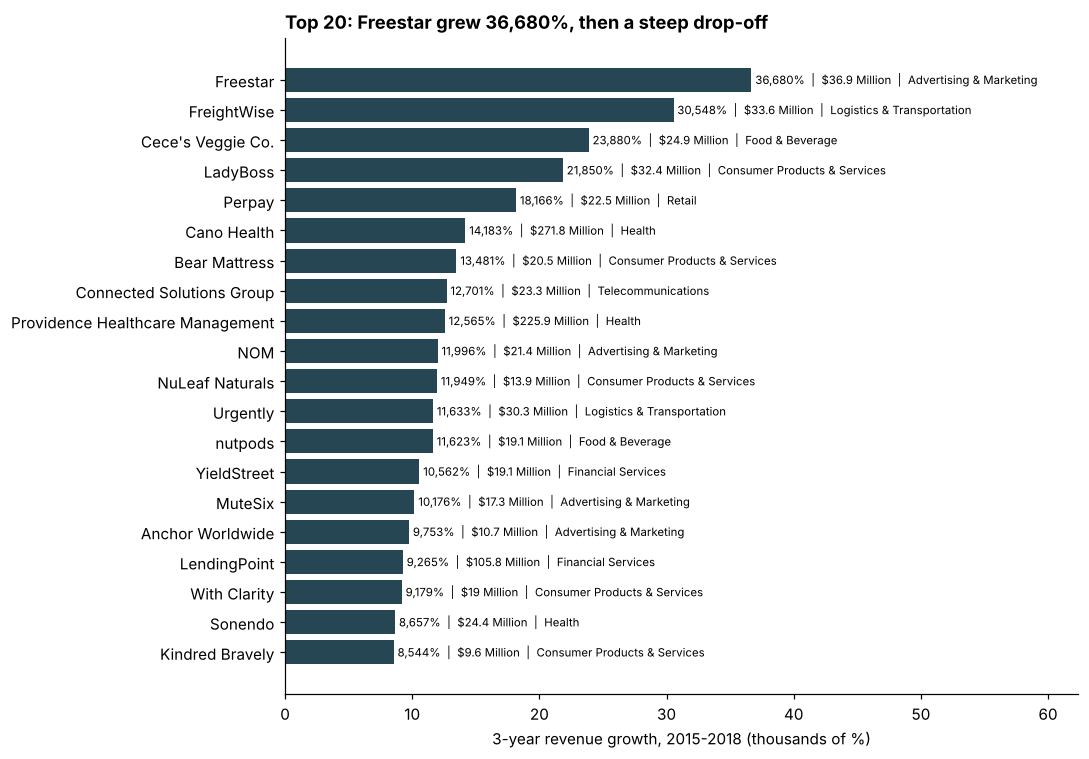

In [6]:
top20 = df.nsmallest(20, "rank").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20.company, top20.growth_rate / 1000, color=DARK)
for y, (g, r, ind) in enumerate(zip(top20.growth_rate, top20.revenue, top20.industry)):
    ax.text(g / 1000 + 0.3, y, f"{g:,.0f}%  |  ${r}  |  {ind}", va="center", fontsize=7.5)
ax.set_xlim(0, top20.growth_rate.max() / 1000 * 1.7)
ax.set_xlabel("3-year revenue growth, 2015-2018 (thousands of %)")
ax.set_title("Top 20: Freestar grew 36,680%, then a steep drop-off")
fig.tight_layout(); fig.savefig(IMG / "top20_growth.png"); plt.show()

## 6. Industries: where growth companies are, and where they grow fastest

In [7]:
ind = (df.groupby("industry")
         .agg(company_count=("company", "size"), median_growth=("growth_rate", "median"),
              average_growth=("growth_rate", "mean"), median_revenue_m=("revenue_usd", lambda s: s.median() / 1e6),
              jobs=("employees", "sum"))
         .sort_values("company_count", ascending=False))
ind.round(1).to_csv(OUT / "industry_summary.csv")
ind.round(1).head(10)

,company_count,median_growth,average_growth,median_revenue_m,jobs
industry,,,,,
Business Products & Services,492,149.4,313.5,9.0,181352.0
Advertising & Marketing,489,157.5,486.7,7.3,49119.0
Software,461,186.3,524.7,8.9,60287.0
Health,356,169.1,546.9,15.7,130695.0
Construction,350,137.7,358.1,12.2,47676.0
Consumer Products & Services,315,174.0,685.6,9.3,55030.0
IT Management,276,127.1,275.4,8.0,35230.0
Financial Services,239,148.1,423.9,12.5,36016.0
Government Services,236,189.7,485.3,13.9,36773.0


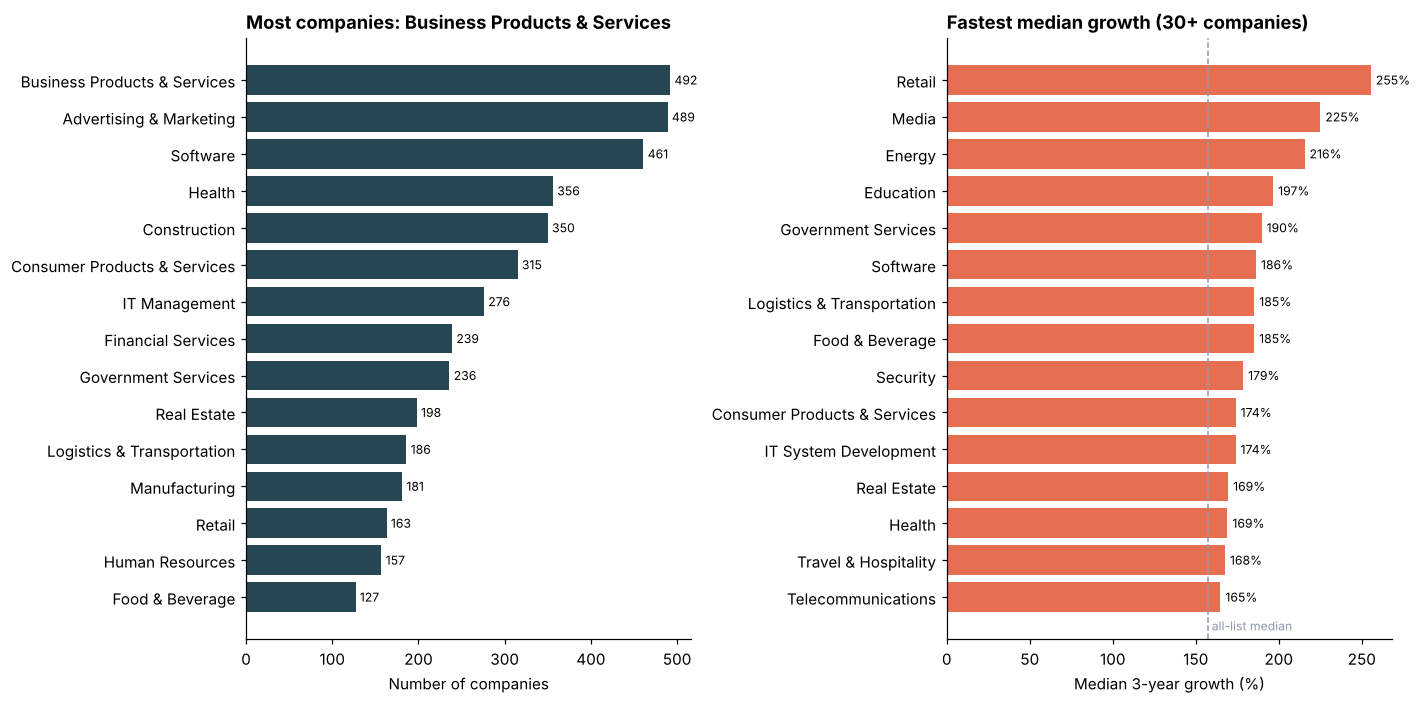

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.5))
top15 = ind.head(15).iloc[::-1]
a1.barh(top15.index, top15.company_count, color=DARK)
for y, v in enumerate(top15.company_count):
    a1.text(v + 5, y, str(v), va="center", fontsize=8)
a1.set_title("Most companies: Business Products & Services")
a1.set_xlabel("Number of companies")

fast = ind[ind.company_count >= 30].sort_values("median_growth").tail(15)
a2.barh(fast.index, fast.median_growth, color=ACCENT)
a2.axvline(df.growth_rate.median(), color=GREY, ls="--", lw=1)
a2.text(df.growth_rate.median(), -0.9, " all-list median", color=GREY, fontsize=8)
for y, v in enumerate(fast.median_growth):
    a2.text(v + 3, y, f"{v:.0f}%", va="center", fontsize=8)
a2.set_title("Fastest median growth (30+ companies)")
a2.set_xlabel("Median 3-year growth (%)")
fig.tight_layout(); fig.savefig(IMG / "industries.png"); plt.show()

In [9]:
leader = ind[ind.company_count >= 30].median_growth.idxmax()
print(f"Largest industry: {ind.index[0]} ({ind.company_count.iloc[0]} companies)")
print(f"Fastest median growth (30+ companies): {leader} ({ind.loc[leader, 'median_growth']:.0f}%)")

Largest industry: Business Products & Services (492 companies)
Fastest median growth (30+ companies): Retail (255%)


Business Products & Services, Software and Advertising & Marketing supply the **most** companies, but that isn't the same as growing **fastest**. Ranking by median growth (30+ companies only, to avoid tiny groups) shows which sectors produce unusually fast growers.

## 7. Locations: states and cities

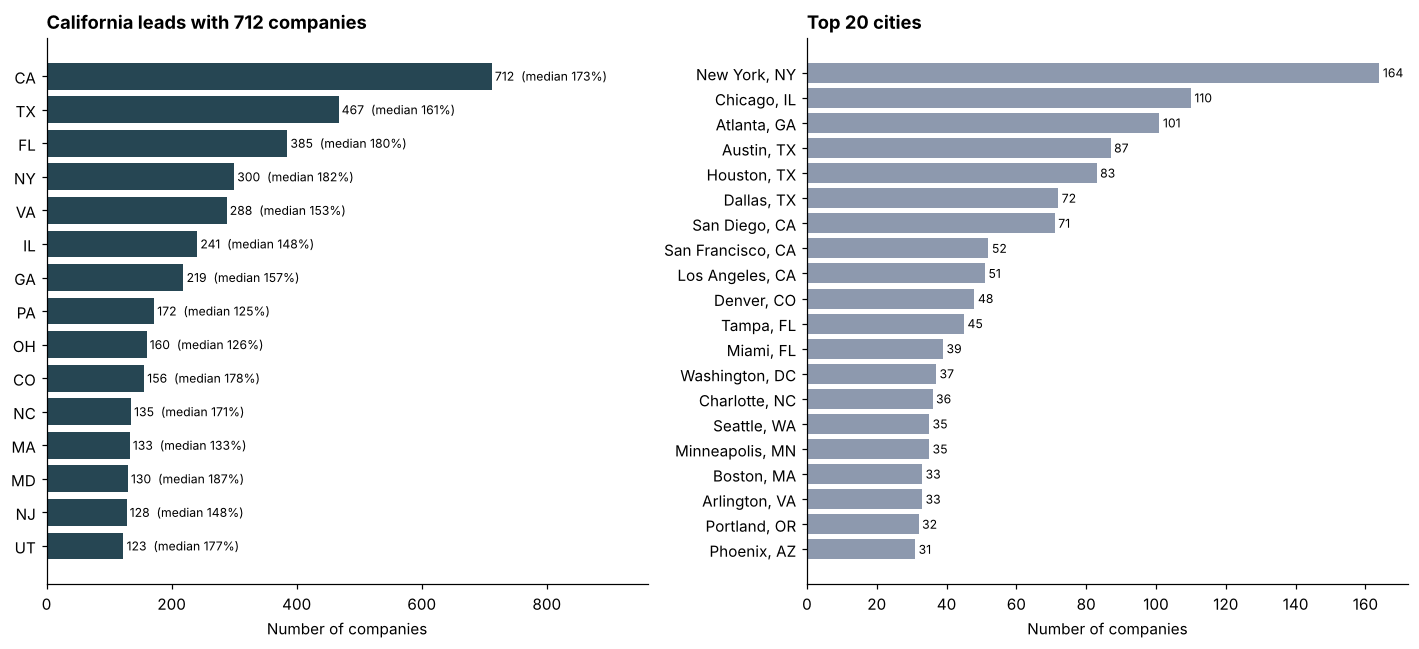

,company_count,median_growth,jobs
state,,,
CA,712,173.3,391573.0
TX,467,161.4,79421.0
FL,385,180.2,77154.0
NY,300,181.9,45607.0
VA,288,152.5,39828.0
IL,241,147.6,56444.0
GA,219,156.8,38553.0
PA,172,124.8,31660.0
OH,160,126.5,33901.0


In [10]:
st = (df.groupby("state").agg(company_count=("company", "size"), median_growth=("growth_rate", "median"),
                              jobs=("employees", "sum"))
        .sort_values("company_count", ascending=False))
st.round(1).to_csv(OUT / "state_summary.csv")
city = (df.assign(place=df.city + ", " + df.state).groupby("place")
          .agg(company_count=("company", "size"), median_growth=("growth_rate", "median"))
          .sort_values("company_count", ascending=False))
city.round(1).to_csv(OUT / "city_summary.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6))
s15 = st.head(15).iloc[::-1]
a1.barh(s15.index, s15.company_count, color=DARK)
for y, (v, m) in enumerate(zip(s15.company_count, s15.median_growth)):
    a1.text(v + 5, y, f"{v}  (median {m:.0f}%)", va="center", fontsize=8)
a1.set_xlim(0, s15.company_count.max() * 1.35)
a1.set_title(f"California leads with {st.company_count.iloc[0]} companies")
a1.set_xlabel("Number of companies")
c20 = city.head(20).iloc[::-1]
a2.barh(c20.index, c20.company_count, color=GREY)
for y, v in enumerate(c20.company_count):
    a2.text(v + 1, y, str(v), va="center", fontsize=8)
a2.set_title("Top 20 cities")
a2.set_xlabel("Number of companies")
fig.tight_layout(); fig.savefig(IMG / "states_cities.png"); plt.show()
st.head(10).round(1)

**Count and growth rate are different things.** A state can have many companies without having the fastest typical growth. Each bar's label shows the state's median growth, so you can compare both at once.

## 8. Company size and age: do smaller and younger companies grow faster?

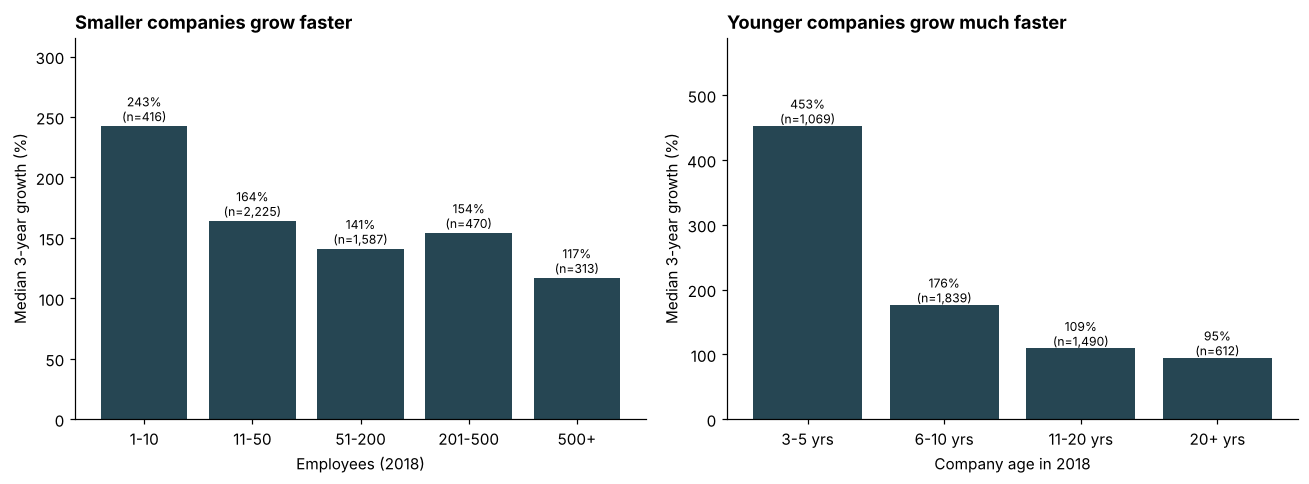

Spearman correlation: growth vs employees -0.13, growth vs company age -0.53


company_count  median_growth
by size 1-10                 416          242.6
        11-50               2225          164.2
        51-200              1587          141.2
        201-500              470          154.3
        500+                 313          117.0
by age  3-5 yrs             1069          452.5
        6-10 yrs            1839          176.4
        11-20 yrs           1490          109.4
        20+ yrs              612           94.8

In [11]:
bands = pd.cut(df.employees, [-1, 10, 50, 200, 500, np.inf], labels=["1-10", "11-50", "51-200", "201-500", "500+"])
age_bands = pd.cut(df.company_age_2018, [2, 5, 10, 20, np.inf], labels=["3-5 yrs", "6-10 yrs", "11-20 yrs", "20+ yrs"])
size = df.groupby(bands, observed=True).agg(company_count=("company", "size"), median_growth=("growth_rate", "median"))
age = df.groupby(age_bands, observed=True).agg(company_count=("company", "size"), median_growth=("growth_rate", "median"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t, title, xl in [(a1, size, "Smaller companies grow faster", "Employees (2018)"),
                         (a2, age, "Younger companies grow much faster", "Company age in 2018")]:
    ax.bar(t.index.astype(str), t.median_growth, color=DARK)
    for x, (m, n) in enumerate(zip(t.median_growth, t.company_count)):
        ax.text(x, m + 4, f"{m:.0f}%\n(n={n:,})", ha="center", fontsize=8)
    ax.set_ylim(0, t.median_growth.max() * 1.3)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel("Median 3-year growth (%)")
fig.tight_layout(); fig.savefig(IMG / "growth_by_size_age.png"); plt.show()
rho_size = df[["growth_rate", "employees"]].corr("spearman").iloc[0, 1]
rho_age = df[["growth_rate", "company_age_2018"]].corr("spearman").iloc[0, 1]
print(f"Spearman correlation: growth vs employees {rho_size:.2f}, growth vs company age {rho_age:.2f}")
pd.concat({"by size": size, "by age": age}).round(1)

Growth rates are **percentages**, so a small base makes high percentages easier. That is part of why smaller and younger companies dominate the top of the list. The relationship is real but modest: both Spearman correlations are weak and negative.

## 9. Growth and hiring: does revenue growth create jobs?

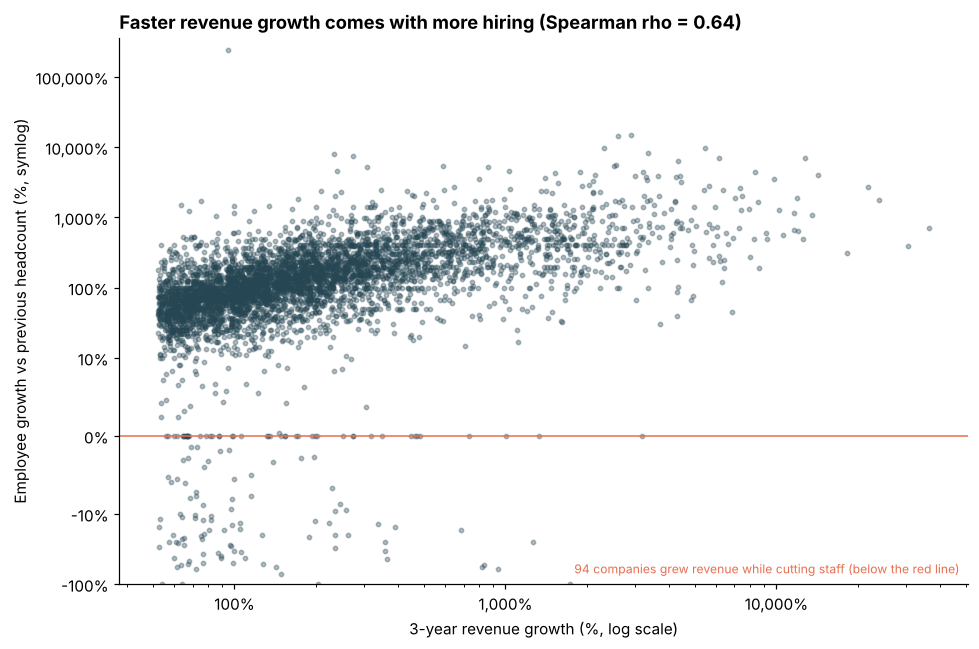

Jobs added between the two headcount figures: 656,830
Median employee growth: 125%


In [12]:
gh = df.dropna(subset=["employee_growth_pct"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(gh.growth_rate, gh.employee_growth_pct.clip(lower=-99), s=8, alpha=0.35, color=DARK)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(-100, gh.employee_growth_pct.max() * 1.5)
pct = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}%")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.axhline(0, color=ACCENT, lw=1)
rho = gh[["growth_rate", "employee_growth_pct"]].corr("spearman").iloc[0, 1]
shrank = (gh.employee_growth_pct < 0).sum()
ax.set_xlabel("3-year revenue growth (%, log scale)")
ax.set_ylabel("Employee growth vs previous headcount (%, symlog)")
ax.set_title(f"Faster revenue growth comes with more hiring (Spearman rho = {rho:.2f})")
ax.text(0.99, 0.02, f"{shrank} companies grew revenue while cutting staff (below the red line)",
        transform=ax.transAxes, ha="right", fontsize=8, color=ACCENT)
fig.tight_layout(); fig.savefig(IMG / "growth_vs_hiring.png"); plt.show()
print(f"Jobs added between the two headcount figures: {int(gh.employees.sum() - gh.employees_prev.sum()):,}")
print(f"Median employee growth: {gh.employee_growth_pct.median():.0f}%")

## 10. Top 1,000 vs the rest

In [13]:
comp = df.groupby(np.where(df.top_1000, "Top 1,000", "Ranks 1,001-5,000")).agg(
    companies=("company", "size"), median_growth=("growth_rate", "median"),
    median_revenue_m=("revenue_usd", lambda s: s.median() / 1e6), median_employees=("employees", "median"),
    median_age=("company_age_2018", "median"), median_employee_growth=("employee_growth_pct", "median"),
    first_time_on_list_pct=("yrs_on_list", lambda s: (s == 1).mean() * 100))
comp.round(1)

,companies,median_growth,median_revenue_m,median_employees,median_age,median_employee_growth,first_time_on_list_pct
"Ranks 1,001-5,000",4010,124.1,11.1,50.0,10.0,100.0,31.6
"Top 1,000",1002,869.2,8.0,39.0,5.0,400.0,58.4


The Top 1,000 are **younger, smaller, and mostly first-time honorees**. Very fast percentage growth is mostly a feature of early-stage companies.

## 11. Target list: top 100 growth companies

In [14]:
target = (df.sort_values(["rank", "growth_rate"], ascending=[True, False])
            [["rank", "company", "industry", "growth_rate", "revenue", "employees", "employee_growth_pct",
              "city", "state", "founded", "url"]]
            .head(100))
target.round(1).to_csv(OUT / "top_100_target_companies.csv", index=False)
target.head(10).round(1)

,rank,company,industry,growth_rate,revenue,employees,employee_growth_pct,city,state,founded,url
0,1,Freestar,Advertising & Marketing,36680.4,36.9 Million,40.0,700.0,Phoenix,AZ,2015.0,http://freestar.com
1,2,FreightWise,Logistics & Transportation,30547.9,33.6 Million,39.0,387.5,Brentwood,TN,2015.0,http://freightwisellc.com
2,3,Cece's Veggie Co.,Food & Beverage,23880.5,24.9 Million,190.0,1800.0,Austin,TX,2015.0,http://cecesveggieco.com
3,4,LadyBoss,Consumer Products & Services,21849.9,32.4 Million,57.0,2750.0,Albuquerque,NM,2014.0,http://ladyboss.com
4,5,Perpay,Retail,18166.4,22.5 Million,25.0,316.7,Philadelphia,PA,2014.0,http://perpay.com
5,6,Cano Health,Health,14183.4,271.8 Million,742.0,4022.2,Miami,FL,2009.0,http://canohealth.com
6,7,Bear Mattress,Consumer Products & Services,13480.7,20.5 Million,12.0,1100.0,Hoboken,NJ,2014.0,http://bearmattress.com
7,8,Connected Solutions Group,Telecommunications,12700.7,23.3 Million,72.0,7100.0,Mechanicsville,VA,2015.0,http://csgstore.net
8,9,Providence Healthcare Management,Health,12564.5,225.9 Million,60.0,500.0,Cleveland,OH,2008.0,http://providencehcm.com
9,10,NOM,Advertising & Marketing,11996.3,21.4 Million,37.0,640.0,Los Angeles,CA,2014.0,http://thisisnom.co


`output/top_100_target_companies.csv` holds the 100 fastest growers. Filter it by industry, state or size for a specific purpose, such as sales outreach to fast-hiring software firms in Texas.

## 12. Key findings

In [15]:
fast_ind = ind[ind.company_count >= 30].median_growth
young, old = age.median_growth.iloc[0], age.median_growth.iloc[-1]
findings = [
    f"The list has {len(df):,} companies from {df.industry.nunique()} industries and {df.state.nunique()} states/territories; typical (median) growth was {df.growth_rate.median():.0f}% over 3 years, while the average ({df.growth_rate.mean():.0f}%) is inflated by a few extreme growers.",
    f"{ind.index[0]} has the most companies ({ind.company_count.iloc[0]}), followed by {ind.index[1]} ({ind.company_count.iloc[1]}) and {ind.index[2]} ({ind.company_count.iloc[2]}).",
    f"{fast_ind.idxmax()} has the fastest median growth ({fast_ind.max():.0f}%) among industries with 30+ companies.",
    f"{st.index[0]} has the most companies ({st.company_count.iloc[0]}), then {st.index[1]} ({st.company_count.iloc[1]}) and {st.index[2]} ({st.company_count.iloc[2]}); the top city is {city.index[0]} ({city.company_count.iloc[0]}).",
    f"Most companies are small: {(bands == '11-50').mean() * 100:.0f}% have 11-50 employees. Companies aged 3-5 years grew a median {young:.0f}% vs {old:.0f}% for those 20+ years old.",
    f"Revenue growth goes with hiring (Spearman rho = {rho:.2f}); headcount rose by {int(gh.employees.sum() - gh.employees_prev.sum()):,} across the list, and only {shrank} companies cut staff.",
    f"Making the Top 1,000 required at least {df.loc[df.top_1000, 'growth_rate'].min():.0f}% growth; {comp.loc['Top 1,000', 'first_time_on_list_pct']:.0f}% of Top-1,000 companies were first-time honorees.",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. The list has 5,012 companies from 27 industries and 51 states/territories; typical (median) growth was 158% over 3 years, while the average (455%) is inflated by a few extreme growers.
2. Business Products & Services has the most companies (492), followed by Advertising & Marketing (489) and Software (461).
3. Retail has the fastest median growth (255%) among industries with 30+ companies.
4. CA has the most companies (712), then TX (467) and FL (385); the top city is New York, NY (164).
5. Most companies are small: 44% have 11-50 employees. Companies aged 3-5 years grew a median 453% vs 95% for those 20+ years old.
6. Revenue growth goes with hiring (Spearman rho = 0.64); headcount rose by 656,830 across the list, and only 94 companies cut staff.
7. Making the Top 1,000 required at least 424% growth; 58% of Top-1,000 companies were first-time honorees.


## Limitations
- **Survivorship and selection.** Inc. 5000 companies apply to be listed and had to be independent, privately held and earning at least $100,000 in 2015. They are not a random sample of U.S. businesses.
- **Percentage growth favors small bases.** Comparisons across size and age partly reflect arithmetic, not only business performance.
- **Revenue is rounded** to $0.1M in the source file.
- **Employee growth** compares 2018 headcount with the file's `previous_workers` figure. The dataset doesn't document which earlier year that is (Inc.'s growth window starts in 2015), so read it as "growth since the earlier headcount", not strictly year over year.
- **Associations, not causes.** Nothing here shows that industry or location *causes* growth.